# HW2: Autoencoder → VAE → f-VAE

The notebook builds three models, each fixing a problem of the previous one:

| Part | Model | What it can do | Its problem |
|---|---|---|---|
| 1 | **Autoencoder (AE)** | compress an image to a few numbers and rebuild it | cannot *generate* new images |
| 2 | **Variational Autoencoder (VAE)** | compress **and** generate | samples are blurry, some are broken ("prior holes") |
| 3 | **f-VAE** = VAE + RealNVP flow | better likelihood and better samples | (bigger and slower) |

Everything runs on MNIST digits **and** Fashion-MNIST.

**How to read it:** every code cell has a short explanation above it. You don't have to understand every line at once; first read the text, run the cell, look at the output.

## 0. Setup
Imports, and choosing the device: `mps` = the GPU of a Mac, `cuda` = an NVIDIA GPU, otherwise the CPU.

In [1]:
import math
import os

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch import nn
from sklearn.decomposition import PCA

if torch.backends.mps.is_available():
    device = 'mps'
elif torch.cuda.is_available():
    device = 'cuda'
else:
    device = 'cpu'
print('device:', device)

os.makedirs('figures', exist_ok=True)      # plots are also saved here (useful for the report)
os.makedirs('checkpoints', exist_ok=True)  # trained models are saved here

device: mps


### Load the data
Same loading code as in the RealNVP homework: the files are raw bytes, the first 16 bytes (images) or 8 bytes (labels) are a header.

We convert pixels from 0..255 to **0..1** and give every image the shape `(1, 28, 28)` = (channels, height, width), which is what convolution layers expect.

Split: **55,000 train / 5,000 validation / 10,000 test**.

In [2]:
DATA = '../CV'   # the data folders from the RealNVP homework


def load_images(path):
    raw = open(path, 'rb').read()
    n = int.from_bytes(raw[4:8], 'big')
    rows = int.from_bytes(raw[8:12], 'big')
    cols = int.from_bytes(raw[12:16], 'big')
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, rows, cols)


def load_labels(path):
    return np.frombuffer(open(path, 'rb').read(), dtype=np.uint8, offset=8)


def load_dataset(train_images, train_labels, test_images, test_labels):
    to_tensor = lambda a: torch.from_numpy(a.copy()).float().div(255).unsqueeze(1)   # (N, 1, 28, 28), values 0..1
    x = to_tensor(load_images(train_images))
    y = torch.from_numpy(load_labels(train_labels).astype(np.int64))
    return {
        'train': x[:55000], 'val': x[55000:],
        'test': to_tensor(load_images(test_images)),
        'test_labels': torch.from_numpy(load_labels(test_labels).astype(np.int64)),
    }


mnist = load_dataset(f'{DATA}/archive/train-images.idx3-ubyte', f'{DATA}/archive/train-labels.idx1-ubyte',
                     f'{DATA}/archive/t10k-images.idx3-ubyte', f'{DATA}/archive/t10k-labels.idx1-ubyte')
fashion = load_dataset(f'{DATA}/fashion/train-images-idx3-ubyte', f'{DATA}/fashion/train-labels-idx1-ubyte',
                       f'{DATA}/fashion/t10k-images-idx3-ubyte', f'{DATA}/fashion/t10k-labels-idx1-ubyte')
DATASETS = {'mnist': mnist, 'fashion': fashion}
FASHION_CLASSES = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']

print('train', mnist['train'].shape, ' val', mnist['val'].shape, ' test', mnist['test'].shape)
print('pixel range:', mnist['train'].min().item(), '...', mnist['train'].max().item())

train torch.Size([55000, 1, 28, 28])  val torch.Size([5000, 1, 28, 28])  test torch.Size([10000, 1, 28, 28])
pixel range: 0.0 ... 1.0


### A helper to draw many images in a grid
We will look at lots of small 28×28 images, so this function puts them into one picture.

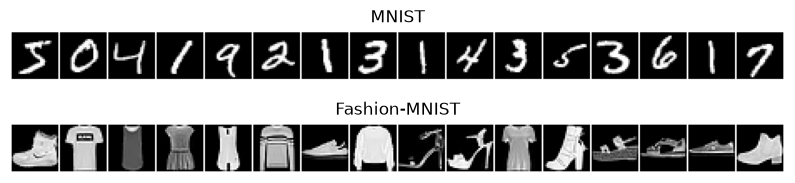

In [3]:
def show_images(images, nrow=1, title=None, ax=None):
    # images: tensor of shape (N, 1, 28, 28) with values in [0, 1]
    images = images.detach().float().cpu().reshape(-1, 28, 28)
    ncol = math.ceil(len(images) / nrow)
    grid = torch.ones(nrow * 29 + 1, ncol * 29 + 1)        # 1-pixel white lines between images
    for i, img in enumerate(images):
        r, c = divmod(i, ncol)
        grid[1 + r * 29: 1 + r * 29 + 28, 1 + c * 29: 1 + c * 29 + 28] = img
    if ax is None:
        plt.figure(figsize=(ncol * 0.7, nrow * 0.7 + 0.5))
        ax = plt.gca()
    ax.imshow(grid, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if title:
        ax.set_title(title)


fig, axes = plt.subplots(2, 1, figsize=(10, 2.2))
show_images(mnist['train'][:16], title='MNIST', ax=axes[0])
show_images(fashion['train'][:16], title='Fashion-MNIST', ax=axes[1])
plt.show()

---
# Part 1: Autoencoder

An autoencoder is two networks trained together:

```
image (784 numbers) ──► ENCODER ──► z (a few numbers, the "code") ──► DECODER ──► rebuilt image (784 numbers)
```

- The **encoder** compresses, the **decoder** decompresses.
- Training goal: the rebuilt image should equal the input → loss = **MSE**(input, output).
- The trick is the **bottleneck**: `z` is small (2…128 numbers), so the network can't just copy pixels. It must learn what digits/clothes *look like*.

### The encoder and decoder
We use the **same** encoder and decoder in all three parts, so the comparisons are fair.

- Encoder: 2 convolutions (each halves the image size: 28 → 14 → 7), then 2 fully-connected layers down to `out_size` numbers.
- Decoder: the mirror image. `ConvTranspose2d` is the "opposite" of a convolution: it doubles the size (7 → 14 → 28).
- The decoder outputs **logits** (any real number). `sigmoid(logit)` turns them into pixel values between 0 and 1.

In [4]:
class Encoder(nn.Module):
    def __init__(self, out_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),    # (1, 28, 28)  -> (32, 14, 14)
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),   # (32, 14, 14) -> (64, 7, 7)
            nn.LeakyReLU(0.2),
            nn.Flatten(),                                            # (64, 7, 7)   -> 3136 numbers
            nn.Linear(64 * 7 * 7, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, out_size),
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_size, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 64 * 7 * 7),
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (64, 7, 7)),                                      # 3136 numbers -> (64, 7, 7)
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # -> (32, 14, 14)
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),    # -> (1, 28, 28)
        )

    def forward(self, z):
        return self.net(z)   # logits


class AutoEncoder(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.encoder = Encoder(latent_size)
        self.decoder = Decoder(latent_size)

    def forward(self, x):
        z = self.encoder(x)
        return torch.sigmoid(self.decoder(z))


# quick shape check
ae = AutoEncoder(latent_size=16)
x = mnist['train'][:4]
print('input:', x.shape, ' code z:', ae.encoder(x).shape, ' output:', ae(x).shape)
print('parameters:', sum(p.numel() for p in ae.parameters()))

input: torch.Size([4, 1, 28, 28])  code z: torch.Size([4, 16])  output: torch.Size([4, 1, 28, 28])
parameters: 3298513


### Training loop
Standard PyTorch loop. Two small details:
- `drop_last=True` drops the last incomplete batch, so every batch has the same size (on a Mac GPU this avoids slow re-compilation).
- After every epoch we measure the **validation MSE** (on images the model never trains on).

In [5]:
@torch.no_grad()
def evaluate_mse(model, images):
    model.eval()
    total = 0
    for x in images.split(1000):
        x = x.to(device)
        total += F.mse_loss(model(x), x, reduction='sum').item()
    return total / images.numel()      # average squared error per pixel


def train_autoencoder(model, data, epochs=10, lr=1e-3, batch_size=128):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(data['train'], batch_size=batch_size, shuffle=True, drop_last=True)
    val_history = []
    for epoch in range(epochs):
        model.train()
        for x in loader:
            x = x.to(device)
            loss = F.mse_loss(model(x), x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        val_history.append(evaluate_mse(model, data['val']))
    return val_history

### Experiment: how does the latent size change the quality?
We train one autoencoder for every latent size `2, 4, …, 128` on both datasets (14 models, 10 epochs each).

**Compression ratio** = 784 / latent size. E.g. latent 16 → each image is stored with 49× fewer numbers.

*(This cell takes a while, roughly 15–25 minutes on a Mac.)*

In [6]:
LATENT_SIZES = [2, 4, 8, 16, 32, 64, 128]
ae_test_mse = {'mnist': {}, 'fashion': {}}
ae_val_curves = {'mnist': {}, 'fashion': {}}
ae_models = {}

for name, data in DATASETS.items():
    for d in LATENT_SIZES:
        torch.manual_seed(0)
        model = AutoEncoder(d)
        ae_val_curves[name][d] = train_autoencoder(model, data, epochs=10)
        ae_test_mse[name][d] = evaluate_mse(model, data['test'])
        ae_models[(name, d)] = model
        print(f'{name:8s} latent {d:3d}  ({784 // d:3d}x compression)   test MSE {ae_test_mse[name][d]:.4f}')

mnist    latent   2  (392x compression)   test MSE 0.0386


mnist    latent   4  (196x compression)   test MSE 0.0262


mnist    latent   8  ( 98x compression)   test MSE 0.0137


mnist    latent  16  ( 49x compression)   test MSE 0.0064


mnist    latent  32  ( 24x compression)   test MSE 0.0034


mnist    latent  64  ( 12x compression)   test MSE 0.0024


... (4 outputs left out)

fashion  latent  16  ( 49x compression)   test MSE 0.0090


fashion  latent  32  ( 24x compression)   test MSE 0.0068


fashion  latent  64  ( 12x compression)   test MSE 0.0054


fashion  latent 128  (  6x compression)   test MSE 0.0048


### Baseline: PCA
PCA is the classic *linear* compression method. A linear autoencoder trained with MSE learns exactly the PCA solution, so comparing against PCA shows how much the **non-linear** network actually helps.

In [7]:
pca_test_mse = {'mnist': {}, 'fashion': {}}
for name, data in DATASETS.items():
    train_flat = data['train'].reshape(-1, 784).numpy()
    test_flat = data['test'].reshape(-1, 784).numpy()
    for d in LATENT_SIZES:
        pca = PCA(n_components=d, random_state=0).fit(train_flat)
        rebuilt = pca.inverse_transform(pca.transform(test_flat)).clip(0, 1)
        pca_test_mse[name][d] = float(((rebuilt - test_flat) ** 2).mean())

table = pd.DataFrame({
    'compression': [f'{784 // d}x' for d in LATENT_SIZES],
    'MNIST AE': [ae_test_mse['mnist'][d] for d in LATENT_SIZES],
    'MNIST PCA': [pca_test_mse['mnist'][d] for d in LATENT_SIZES],
    'Fashion AE': [ae_test_mse['fashion'][d] for d in LATENT_SIZES],
    'Fashion PCA': [pca_test_mse['fashion'][d] for d in LATENT_SIZES],
}, index=pd.Index(LATENT_SIZES, name='latent size'))
table.round(4)

,compression,MNIST AE,MNIST PCA,Fashion AE,Fashion PCA
latent size,,,,,
2,392x,0.0386,0.0555,0.0272,0.0456
4,196x,0.0262,0.0474,0.0184,0.0359
8,98x,0.0137,0.0364,0.0124,0.0260
16,49x,0.0064,0.0254,0.0090,0.0198
32,24x,0.0034,0.0152,0.0068,0.0145
64,12x,0.0024,0.0078,0.0054,0.0098
128,6x,0.0023,0.0034,0.0048,0.0059


### Plot: reconstruction error vs latent size
Both axes are logarithmic. Look for the **"elbow"**: the point after which a bigger code barely helps.

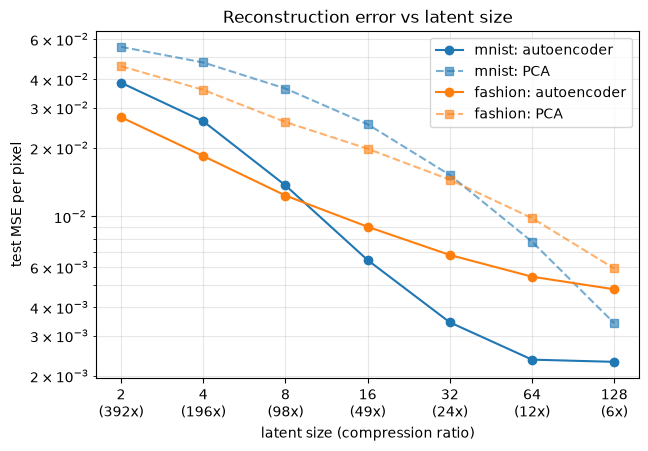

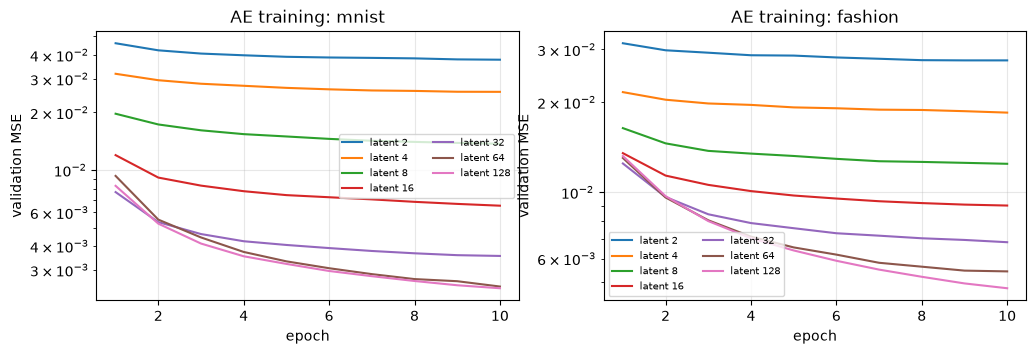

In [8]:
plt.figure(figsize=(7, 4.5))
for name, color in [('mnist', 'C0'), ('fashion', 'C1')]:
    plt.plot(LATENT_SIZES, [ae_test_mse[name][d] for d in LATENT_SIZES], 'o-', color=color, label=f'{name}: autoencoder')
    plt.plot(LATENT_SIZES, [pca_test_mse[name][d] for d in LATENT_SIZES], 's--', color=color, alpha=0.6, label=f'{name}: PCA')
plt.xscale('log', base=2)
plt.yscale('log')
plt.xticks(LATENT_SIZES, [f'{d}\n({784 // d}x)' for d in LATENT_SIZES])
plt.xlabel('latent size (compression ratio)')
plt.ylabel('test MSE per pixel')
plt.title('Reconstruction error vs latent size')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.savefig('figures/part1_mse_vs_latent.png', dpi=120, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, name in zip(axes, DATASETS):
    for d in LATENT_SIZES:
        ax.plot(range(1, 11), ae_val_curves[name][d], label=f'latent {d}')
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('validation MSE'); ax.set_title(f'AE training: {name}')
    ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.show()

### Look at the reconstructions
Top row = original test images. Every next row = the same images after going through an autoencoder with a bigger code.

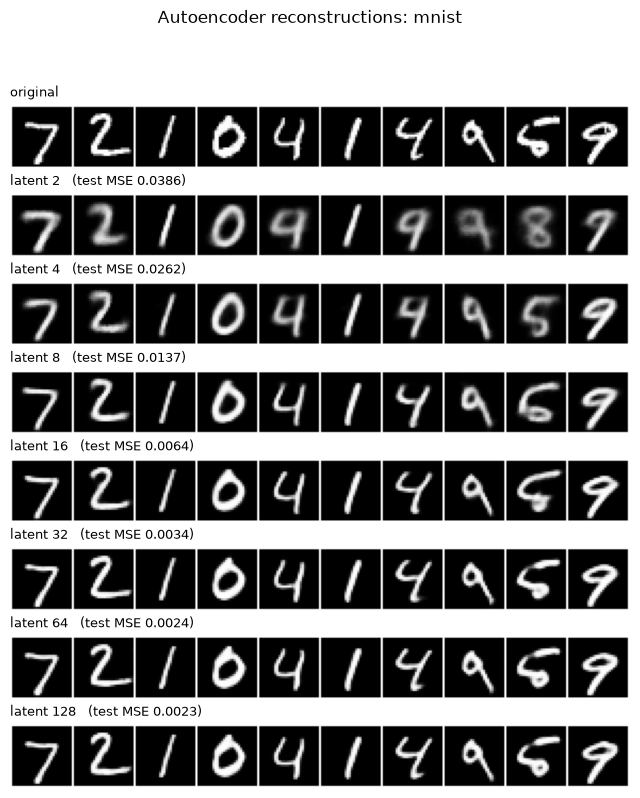

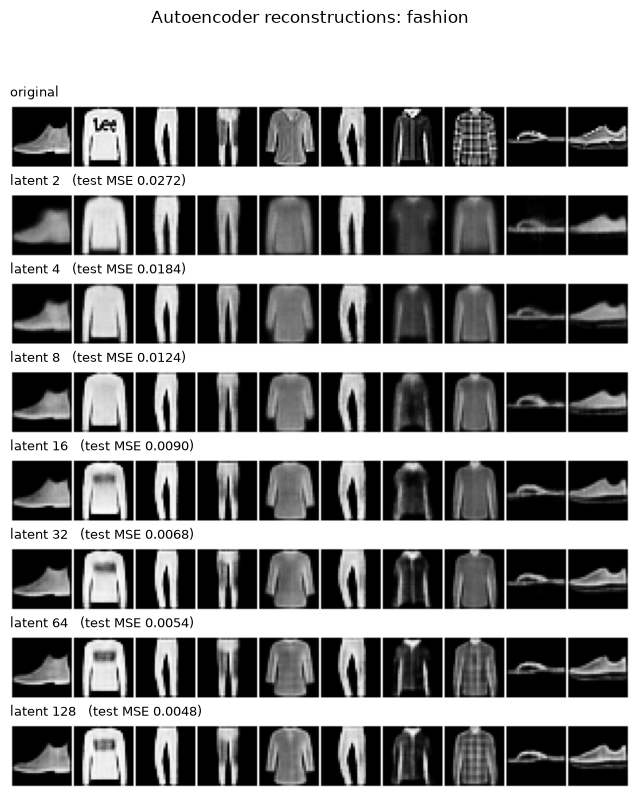

In [9]:
for name, data in DATASETS.items():
    x = data['test'][:10]
    fig, axes = plt.subplots(len(LATENT_SIZES) + 1, 1, figsize=(8, 9))
    show_images(x, ax=axes[0])
    axes[0].set_title('original', loc='left', fontsize=9)
    for ax, d in zip(axes[1:], LATENT_SIZES):
        model = ae_models[(name, d)].eval()
        with torch.no_grad():
            show_images(model(x.to(device)), ax=ax)
        ax.set_title(f'latent {d}   (test MSE {ae_test_mse[name][d]:.4f})', loc='left', fontsize=9)
    fig.suptitle(f'Autoencoder reconstructions: {name}')
    plt.savefig(f'figures/part1_reconstructions_{name}.png', dpi=120, bbox_inches='tight')
    plt.show()

### Can a plain autoencoder generate new images?
Idea: pick a *random* code `z` and decode it. We try two ways:
1. `z ~ N(0, I)`: random numbers around 0 with spread 1.
2. A Gaussian **fitted to the real codes** of the training images (same mean and covariance), which is the fairest possible guess.

The AE was never told *where* its codes should live, so we don't really know which `z` values are "valid".

spread (std) of the real codes per dimension: from 1.75 to 2.66 (a standard normal would have 1)


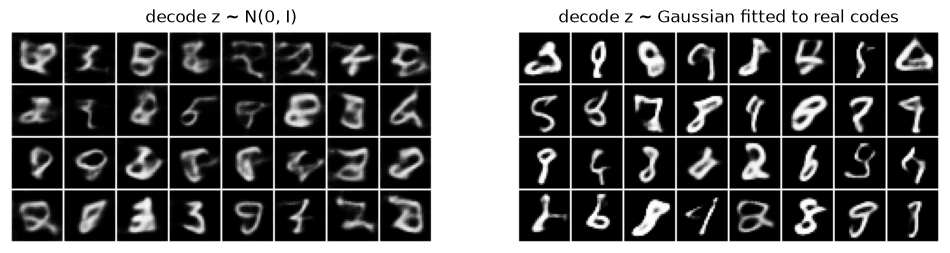

In [10]:
ae16 = ae_models[('mnist', 16)].eval()
with torch.no_grad():
    codes = torch.cat([ae16.encoder(x.to(device)) for x in mnist['train'].split(1000)])
    print('spread (std) of the real codes per dimension: from', round(codes.std(0).min().item(), 2),
          'to', round(codes.std(0).max().item(), 2), '(a standard normal would have 1)')

    z_random = torch.randn(32, 16, device=device)
    fitted = torch.distributions.MultivariateNormal(codes.mean(0).cpu(), torch.cov(codes.T).cpu() + 1e-4 * torch.eye(16))
    z_fitted = fitted.sample((32,)).to(device)

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
    show_images(torch.sigmoid(ae16.decoder(z_random)), nrow=4, title='decode z ~ N(0, I)', ax=axes[0])
    show_images(torch.sigmoid(ae16.decoder(z_fitted)), nrow=4, title='decode z ~ Gaussian fitted to real codes', ax=axes[1])
    plt.savefig('figures/part1_ae_random_decode.png', dpi=120, bbox_inches='tight')
    plt.show()

**What to notice:** with `N(0, I)` we get mostly garbage. The fitted Gaussian is better, but many images are still broken or mixed digits. The codes form separate clumps with **empty holes** between them, and the decoder has never seen those holes.

→ This is exactly why we need the **VAE**: it *forces* the codes to fill a known distribution that we can sample from.

---
# Part 2: Variational Autoencoder (VAE)

Three changes compared to the autoencoder:

**1. The encoder outputs a cloud, not a point.**
For each image it outputs two vectors: a center **μ** and a spread **σ** (we store log σ² because a network can output any number, while σ must be positive).
"This image's code is somewhere around μ, give or take σ."

**2. The loss gets a second term.**

$$\text{loss} = \underbrace{\text{BCE}(x, \hat{x})}_{\text{reconstruction: rebuild the image}} + \underbrace{\text{KL}\big(\mathcal{N}(\mu, \sigma^2)\ \|\ \mathcal{N}(0, I)\big)}_{\text{keep every cloud close to } \mathcal{N}(0,I)}$$

This sum is the **negative ELBO**. It's an upper bound on −log p(x), so minimizing it pushes up the likelihood of the data.
The KL term pulls all clouds together into one round blob around 0, so there are **no holes**, and later we can sample `z ~ N(0, I)`.

KL in closed form: $\;\text{KL} = -\tfrac12 \sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$

**3. The reparameterization trick.**
We need a random `z` from the cloud, but you can't backpropagate through "pick a random number". So we write
$z = \mu + \sigma \cdot \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, I)$: the randomness sits in ε, and gradients flow through μ and σ.

### Why BCE, and "binarization"
The decoder outputs, for each pixel, the **probability that it is white** (a coin flip = Bernoulli). The log-likelihood of a Bernoulli is exactly −BCE.
For that to be a proper probability, the target pixels must be 0 or 1. So every batch we turn each gray pixel into 0/1 at random, with P(1) = its brightness (**dynamic binarization**). The decoder then learns the *average*, i.e. the grayscale image.
For validation/test we binarize **once** with a fixed seed, so all models are scored on exactly the same images.

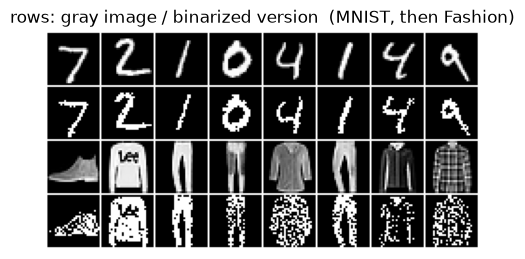

In [11]:
generator = torch.Generator().manual_seed(1)
for data in DATASETS.values():
    data['val_bin'] = torch.bernoulli(data['val'], generator=generator)
    data['test_bin'] = torch.bernoulli(data['test'], generator=generator)

show_images(torch.cat([mnist['test'][:8], mnist['test_bin'][:8], fashion['test'][:8], fashion['test_bin'][:8]]),
            nrow=4, title='rows: gray image / binarized version  (MNIST, then Fashion)')
plt.show()

### The VAE model
- `encode` returns μ and log σ² (the encoder simply outputs `2 × latent_size` numbers, which we split in half).
- `forward` samples `z` with the reparameterization trick and decodes it.
- `kl` = the closed-form KL from above. (In Part 3 we will replace only this method and `log_prior`.)
- `sample` generates new images: `z ~ N(0, I)` → decoder.

`temperature` < 1 samples closer to the center of the prior: cleaner but less varied images.

In [12]:
LOG_2PI = math.log(2 * math.pi)


def log_normal(z, mu, logvar):
    # log of the Gaussian density N(z; mu, sigma^2), summed over latent dimensions -> one number per image
    return (-0.5 * (z - mu) ** 2 / logvar.exp() - 0.5 * logvar - 0.5 * LOG_2PI).sum(dim=1)


class VAE(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.latent_size = latent_size
        self.encoder = Encoder(2 * latent_size)       # outputs mu AND log-variance
        self.decoder = Decoder(latent_size)

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1)
        return mu, logvar.clamp(-12, 8)               # clamp only for numerical safety

    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps        # reparameterization trick
        return self.decoder(z), z, mu, logvar

    def kl(self, z, mu, logvar):
        # KL( N(mu, sigma^2) || N(0, I) ), closed form
        return -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)

    def log_prior(self, z):
        # log N(z; 0, I)
        return (-0.5 * z ** 2 - 0.5 * LOG_2PI).sum(dim=1)

    @torch.no_grad()
    def sample_z(self, n, temperature=1.0):
        return torch.randn(n, self.latent_size, device=device) * temperature

    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        return torch.sigmoid(self.decoder(self.sample_z(n, temperature)))


def loss_terms(model, x):
    # returns reconstruction loss and KL, one number per image (in nats)
    logits, z, mu, logvar = model(x)
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction='none').sum(dim=(1, 2, 3))
    kl = model.kl(z, mu, logvar)
    return recon, kl

### Training loop, with KL warm-up
If the KL term is at full strength from the first step, the model may learn to **ignore z** completely ("posterior collapse").
So we multiply KL by **β**, which grows from 0 to 1 during the first 10 epochs (**KL warm-up**). First the model learns to reconstruct, then it is gradually forced to organize the latent space.

We print −ELBO = recon + KL (always with β = 1, so the numbers are comparable).

In [13]:
@torch.no_grad()
def evaluate_vae(model, images):
    model.eval()
    recon_sum, kl_sum = 0, 0
    for x in images.split(1000):
        recon, kl = loss_terms(model, x.to(device))
        recon_sum += recon.sum().item()
        kl_sum += kl.sum().item()
    n = len(images)
    return {'recon': recon_sum / n, 'kl': kl_sum / n, 'nelbo': (recon_sum + kl_sum) / n}


def train_vae(model, data, epochs=40, lr=1e-3, batch_size=128, warmup_epochs=10):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(data['train'], batch_size=batch_size, shuffle=True, drop_last=True)
    warmup_steps = warmup_epochs * len(loader)
    history = {'train': [], 'val': [], 'val_recon': [], 'val_kl': [], 'beta': []}
    step = 0
    for epoch in range(epochs):
        model.train()
        total, count = 0, 0
        for x in loader:
            x = torch.bernoulli(x).to(device)            # dynamic binarization
            beta = min(1.0, step / warmup_steps)          # KL warm-up
            recon, kl = loss_terms(model, x)
            loss = (recon + beta * kl).mean()
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 100)
            optimizer.step()
            step += 1
            total += (recon + kl).sum().item()
            count += len(x)

        val = evaluate_vae(model, data['val_bin'])
        history['train'].append(total / count)
        history['val'].append(val['nelbo'])
        history['val_recon'].append(val['recon'])
        history['val_kl'].append(val['kl'])
        history['beta'].append(beta)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d}/{epochs}  beta {beta:.2f}  train -ELBO {total / count:7.2f}  "
                  f"val -ELBO {val['nelbo']:7.2f}  (recon {val['recon']:6.2f}, KL {val['kl']:5.2f})")
    return history

### Train the VAE (latent size 16) on both datasets
40 epochs each, about 10–15 minutes per dataset on a Mac.

In [14]:
torch.manual_seed(0)
vae_mnist = VAE(16)
hist_vae_mnist = train_vae(vae_mnist, mnist, epochs=40)

epoch  1/40  beta 0.10  train -ELBO  159.39  val -ELBO  119.38  (recon  71.78, KL 47.60)


epoch  5/40  beta 0.50  train -ELBO   99.86  val -ELBO   99.16  (recon  67.25, KL 31.90)


epoch 10/40  beta 1.00  train -ELBO   95.40  val -ELBO   96.28  (recon  69.31, KL 26.97)


epoch 15/40  beta 1.00  train -ELBO   93.93  val -ELBO   94.73  (recon  68.89, KL 25.85)


epoch 20/40  beta 1.00  train -ELBO   92.89  val -ELBO   93.98  (recon  68.41, KL 25.57)


epoch 25/40  beta 1.00  train -ELBO   92.18  val -ELBO   93.44  (recon  68.82, KL 24.62)


epoch 30/40  beta 1.00  train -ELBO   91.54  val -ELBO   92.53  (recon  67.57, KL 24.97)


epoch 35/40  beta 1.00  train -ELBO   91.02  val -ELBO   92.37  (recon  66.60, KL 25.77)


epoch 40/40  beta 1.00  train -ELBO   90.66  val -ELBO   91.78  (recon  66.33, KL 25.45)


In [15]:
torch.manual_seed(0)
vae_fashion = VAE(16)
hist_vae_fashion = train_vae(vae_fashion, fashion, epochs=40)

epoch  1/40  beta 0.10  train -ELBO  296.08  val -ELBO  262.10  (recon 218.04, KL 44.06)


epoch  5/40  beta 0.50  train -ELBO  240.99  val -ELBO  241.80  (recon 214.34, KL 27.46)


epoch 10/40  beta 1.00  train -ELBO  235.84  val -ELBO  237.45  (recon 218.29, KL 19.16)


epoch 15/40  beta 1.00  train -ELBO  234.14  val -ELBO  235.47  (recon 216.54, KL 18.93)


epoch 20/40  beta 1.00  train -ELBO  233.33  val -ELBO  234.88  (recon 216.23, KL 18.65)


epoch 25/40  beta 1.00  train -ELBO  232.80  val -ELBO  234.25  (recon 215.90, KL 18.35)


epoch 30/40  beta 1.00  train -ELBO  232.32  val -ELBO  234.24  (recon 215.83, KL 18.41)


epoch 35/40  beta 1.00  train -ELBO  231.98  val -ELBO  233.67  (recon 214.66, KL 19.01)


epoch 40/40  beta 1.00  train -ELBO  231.78  val -ELBO  233.26  (recon 214.68, KL 18.58)


### Learning curves
Three panels: total −ELBO, the reconstruction part, and the KL part (with β as a dotted line).
Watch what happens to the reconstruction loss *while β grows* during the first 10 epochs.

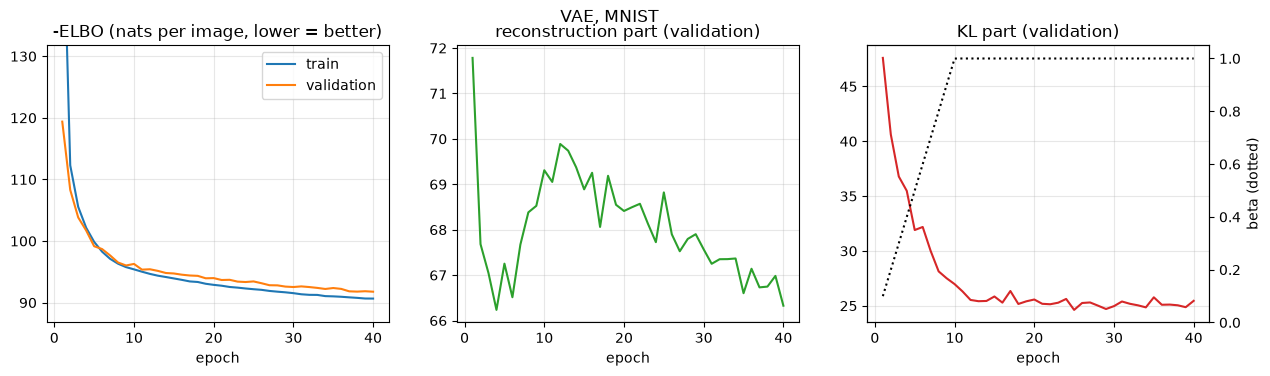

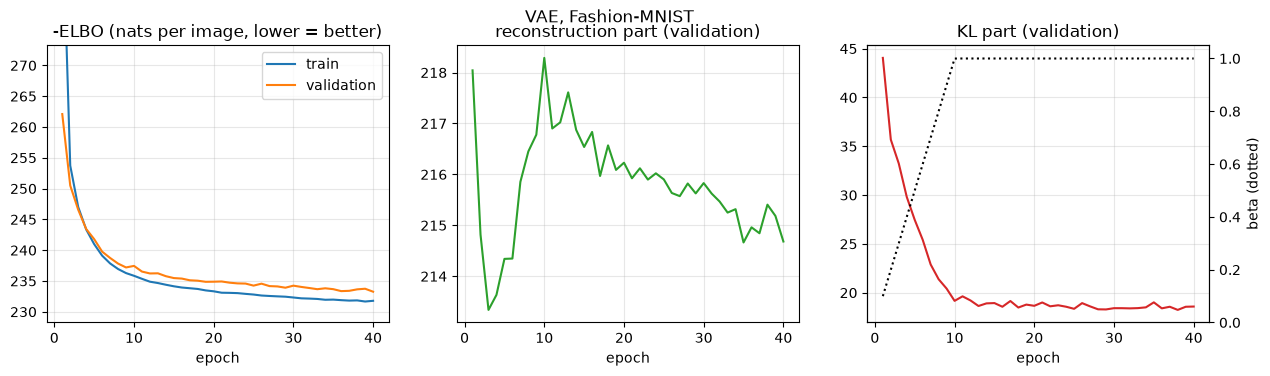

In [16]:
def plot_history(history, title, save_as=None):
    epochs = range(1, len(history['val']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    axes[0].plot(epochs, history['train'], label='train')
    axes[0].plot(epochs, history['val'], label='validation')
    low = min(history['val'][min(3, len(history['val']) - 1):])
    axes[0].set_ylim(low - 5, low + 40)
    axes[0].set_title('-ELBO (nats per image, lower = better)')
    axes[1].plot(epochs, history['val_recon'], color='C2')
    axes[1].set_title('reconstruction part (validation)')
    axes[2].plot(epochs, history['val_kl'], color='C3', label='KL')
    axes[2].set_title('KL part (validation)')
    beta_axis = axes[2].twinx()
    beta_axis.plot(epochs, history['beta'], 'k:', label='beta')
    beta_axis.set_ylim(0, 1.05)
    beta_axis.set_ylabel('beta (dotted)')
    for ax in axes:
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.suptitle(title)
    if save_as:
        plt.savefig(save_as, dpi=120, bbox_inches='tight')
    plt.show()


plot_history(hist_vae_mnist, 'VAE, MNIST', 'figures/part2_vae_curves_mnist.png')
plot_history(hist_vae_fashion, 'VAE, Fashion-MNIST', 'figures/part2_vae_curves_fashion.png')

### Generate new images (sampling from the latent space)
`z ~ N(0, I)` → decoder → image. We show the decoder's *mean* output (pixel probabilities), which looks like a grayscale image.
Left: temperature 1 (the real model). Right: temperature 0.7 (closer to the center → cleaner, less varied).

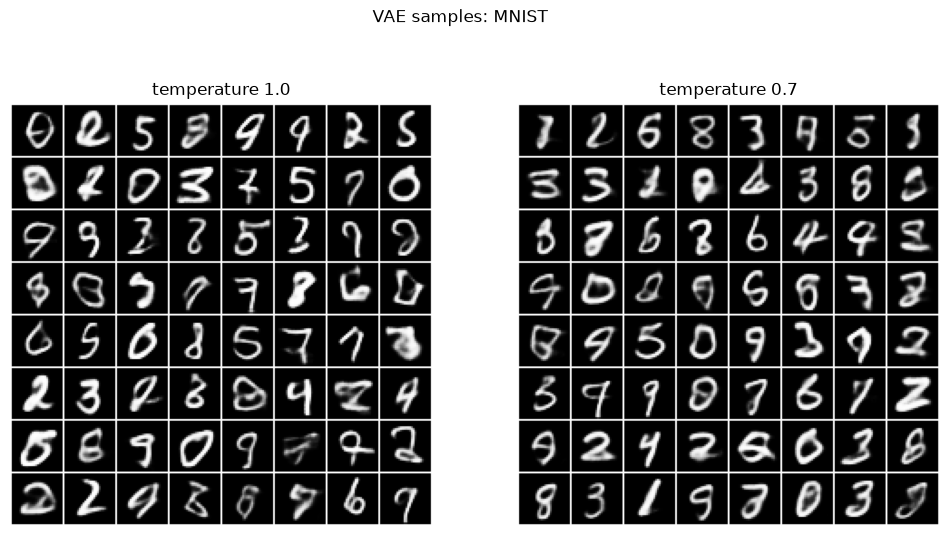

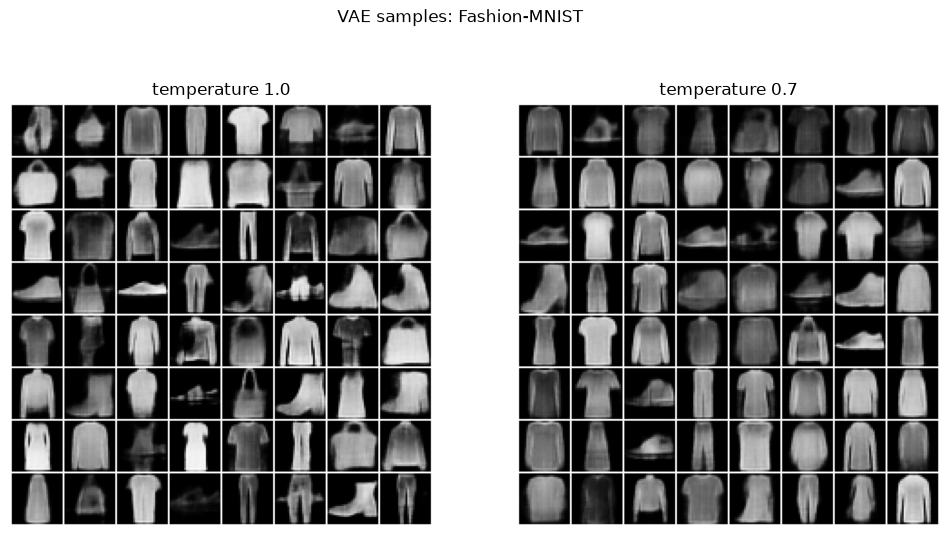

In [17]:
def show_samples(model, title, save_as=None):
    torch.manual_seed(0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.3))
    show_images(model.sample(64, temperature=1.0), nrow=8, title='temperature 1.0', ax=axes[0])
    show_images(model.sample(64, temperature=0.7), nrow=8, title='temperature 0.7', ax=axes[1])
    fig.suptitle(title)
    if save_as:
        plt.savefig(save_as, dpi=120, bbox_inches='tight')
    plt.show()


show_samples(vae_mnist, 'VAE samples: MNIST', 'figures/part2_vae_samples_mnist.png')
show_samples(vae_fashion, 'VAE samples: Fashion-MNIST', 'figures/part2_vae_samples_fashion.png')

### Reconstructions and interpolations
- **Reconstruction:** encode a test image, take the center μ, decode.
- **Interpolation:** take the codes of two test images and walk in a straight line between them. In a good latent space every step in between should still look like a real image (no garbage in the middle).

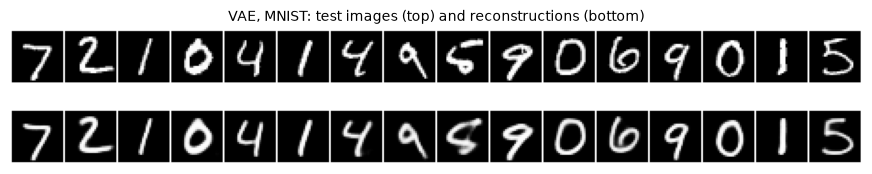

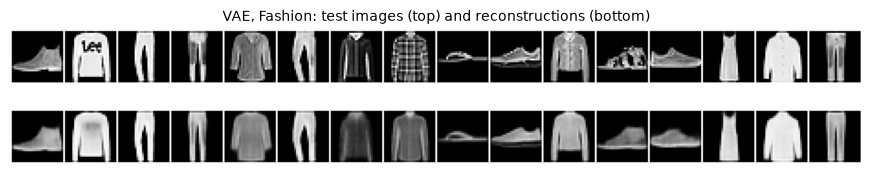

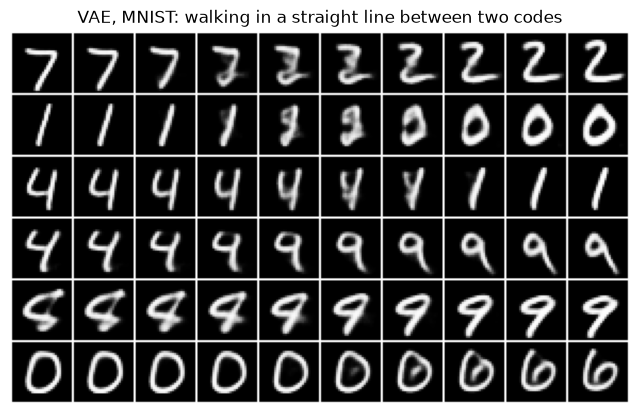

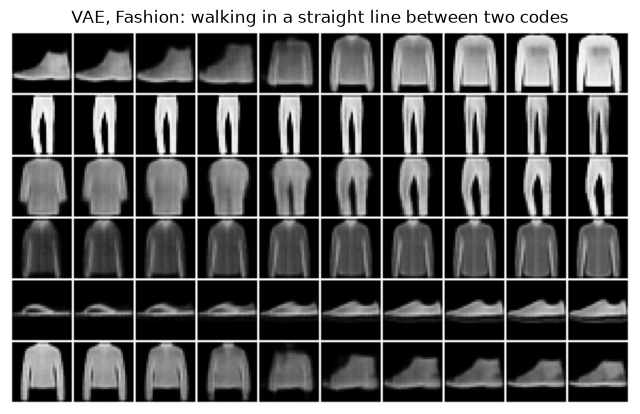

In [18]:
@torch.no_grad()
def show_reconstructions(model, data, title):
    model.eval()
    x = data['test'][:16].to(device)
    mu, _ = model.encode(x)
    fig, axes = plt.subplots(2, 1, figsize=(11, 1.9))
    show_images(x, ax=axes[0])
    show_images(torch.sigmoid(model.decoder(mu)), ax=axes[1])
    axes[0].set_title(f'{title}: test images (top) and reconstructions (bottom)', fontsize=10)
    plt.show()


@torch.no_grad()
def show_interpolations(model, data, title, save_as=None):
    model.eval()
    mu, _ = model.encode(data['test'][:12].to(device))
    start, end = mu[0::2], mu[1::2]                                  # 6 pairs of images
    steps = torch.linspace(0, 1, 10, device=device).view(1, -1, 1)
    z = start.unsqueeze(1) * (1 - steps) + end.unsqueeze(1) * steps  # (6 pairs, 10 steps, latent)
    images = torch.sigmoid(model.decoder(z.reshape(-1, model.latent_size)))
    plt.figure(figsize=(8, 5))
    show_images(images, nrow=6, title=f'{title}: walking in a straight line between two codes', ax=plt.gca())
    if save_as:
        plt.savefig(save_as, dpi=120, bbox_inches='tight')
    plt.show()


show_reconstructions(vae_mnist, mnist, 'VAE, MNIST')
show_reconstructions(vae_fashion, fashion, 'VAE, Fashion')
show_interpolations(vae_mnist, mnist, 'VAE, MNIST', 'figures/part2_vae_interpolation_mnist.png')
show_interpolations(vae_fashion, fashion, 'VAE, Fashion', 'figures/part2_vae_interpolation_fashion.png')

### Measuring likelihood properly (bonus): importance-weighted estimate
−ELBO is only an *upper bound* on the true −log p(x). A tighter estimate (Burda et al., 2016, "IWAE bound"):
draw **K = 100** codes from the encoder's cloud for each image, and average how well each one explains the image, weighted by how likely it is under the prior vs the cloud:

$$\log p(x) \approx \log \frac{1}{K}\sum_{k=1}^{K} \frac{p(x \mid z_k)\, p(z_k)}{q(z_k \mid x)}$$

The more samples, the closer to the true value. We report it as **NLL in nats per image (lower = better)**.

In [19]:
@torch.no_grad()
def iwae_nll(model, images, K=100, batch_size=50):
    model.eval()
    total = 0
    for x in images.split(batch_size):
        x = x.to(device)
        B = len(x)
        mu, logvar = model.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn(K, B, model.latent_size, device=device)   # K codes per image
        z = z.reshape(K * B, -1)
        mu_k, logvar_k = mu.repeat(K, 1), logvar.repeat(K, 1)
        logits = model.decoder(z)
        log_p_x_given_z = -F.binary_cross_entropy_with_logits(logits, x.repeat(K, 1, 1, 1), reduction='none').sum(dim=(1, 2, 3))
        log_weights = (log_p_x_given_z + model.log_prior(z) - log_normal(z, mu_k, logvar_k)).reshape(K, B)
        total += -(torch.logsumexp(log_weights, dim=0) - math.log(K)).sum().item()
    return total / len(images)


def test_metrics(model, data):
    torch.manual_seed(0)
    m = evaluate_vae(model, data['test_bin'])
    m['iwae_nll'] = iwae_nll(model, data['test_bin'])
    return m


results = {}   # we collect the test numbers of every model here
results['VAE (d=16), MNIST'] = test_metrics(vae_mnist, mnist)
results['VAE (d=16), Fashion'] = test_metrics(vae_fashion, fashion)
pd.DataFrame(results).T.round(2)

,recon,kl,nelbo,iwae_nll
"VAE (d=16), MNIST",65.81,25.44,91.25,87.18
"VAE (d=16), Fashion",215.47,18.47,233.94,230.90


### MNIST vs Fashion-MNIST
The likelihood numbers are very different between the datasets, but that mostly measures **how much information** a typical image contains, not how good the model is.
A more useful comparison: which **classes** are hard for the model? We compute the −ELBO for every test image and average per class.

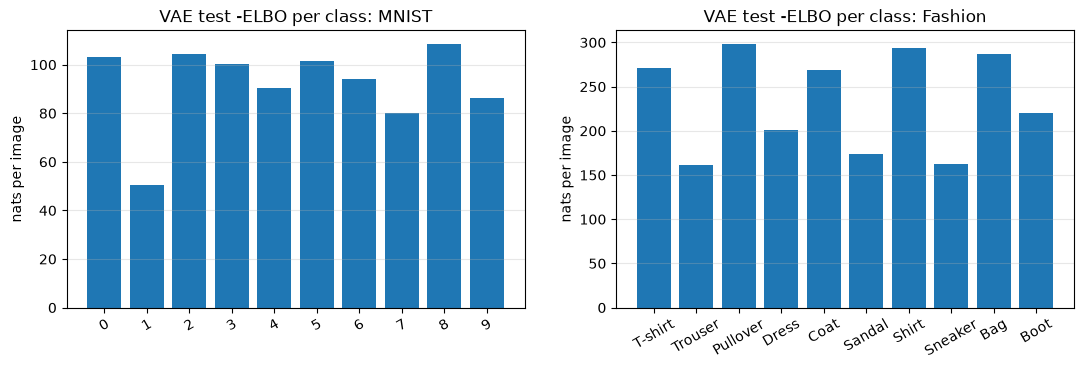

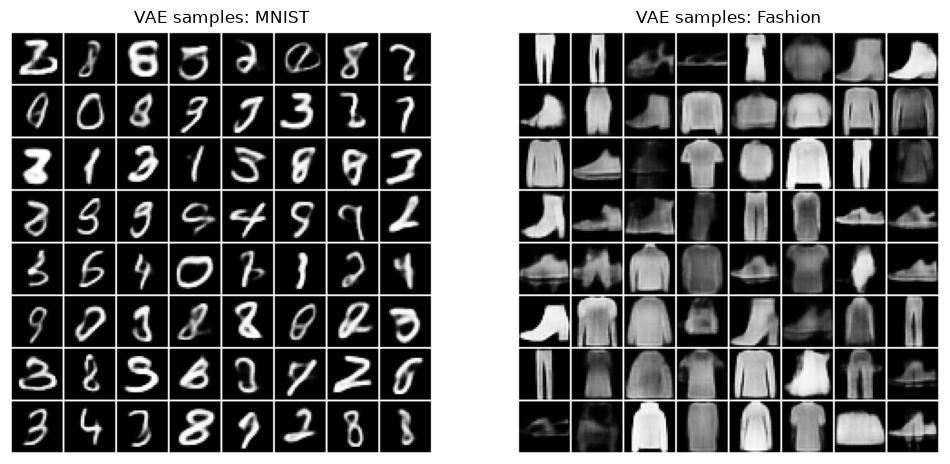

In [20]:
@torch.no_grad()
def nelbo_per_class(model, data, repeats=5):
    model.eval()
    per_image = []
    for x in data['test_bin'].split(1000):
        x = x.to(device)
        values = [sum(loss_terms(model, x)) for _ in range(repeats)]   # average a few random z's
        per_image.append(torch.stack(values).mean(0).cpu())
    per_image = torch.cat(per_image)
    return [per_image[data['test_labels'] == c].mean().item() for c in range(10)]


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (name, model, data, labels) in zip(axes, [('MNIST', vae_mnist, mnist, [str(i) for i in range(10)]),
                                                   ('Fashion', vae_fashion, fashion, FASHION_CLASSES)]):
    ax.bar(labels, nelbo_per_class(model, data), color='C0')
    ax.set_title(f'VAE test -ELBO per class: {name}')
    ax.set_ylabel('nats per image')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3, axis='y')
plt.savefig('figures/part2_per_class.png', dpi=120, bbox_inches='tight')
plt.show()

torch.manual_seed(7)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.3))
show_images(vae_mnist.sample(64), nrow=8, title='VAE samples: MNIST', ax=axes[0])
show_images(vae_fashion.sample(64), nrow=8, title='VAE samples: Fashion', ax=axes[1])
plt.show()

### A 2-dimensional VAE, so we can *see* the latent space
With only 2 latent numbers, every image becomes a point on a plane, which we can plot.
- **Left:** the code centers μ of 5,000 test images (color = class), on top of the prior density (gray).
- **Right:** decode a regular grid of `z` values. This is the "map" the decoder has learned.

epoch  1/20  beta 0.20  train -ELBO  177.50  val -ELBO  160.46  (recon 152.63, KL  7.83)


epoch  5/20  beta 1.00  train -ELBO  150.49  val -ELBO  148.65  (recon 142.44, KL  6.22)


epoch 10/20  beta 1.00  train -ELBO  146.91  val -ELBO  145.43  (recon 139.01, KL  6.41)


epoch 15/20  beta 1.00  train -ELBO  145.32  val -ELBO  144.27  (recon 137.91, KL  6.36)


epoch 20/20  beta 1.00  train -ELBO  144.16  val -ELBO  143.43  (recon 136.92, KL  6.50)


epoch  1/20  beta 0.20  train -ELBO  287.99  val -ELBO  272.39  (recon 263.33, KL  9.07)


epoch  5/20  beta 1.00  train -ELBO  262.30  val -ELBO  264.05  (recon 258.13, KL  5.92)


epoch 10/20  beta 1.00  train -ELBO  260.03  val -ELBO  262.69  (recon 256.33, KL  6.36)


epoch 15/20  beta 1.00  train -ELBO  258.92  val -ELBO  261.16  (recon 254.76, KL  6.40)


epoch 20/20  beta 1.00  train -ELBO  258.03  val -ELBO  259.93  (recon 253.76, KL  6.17)


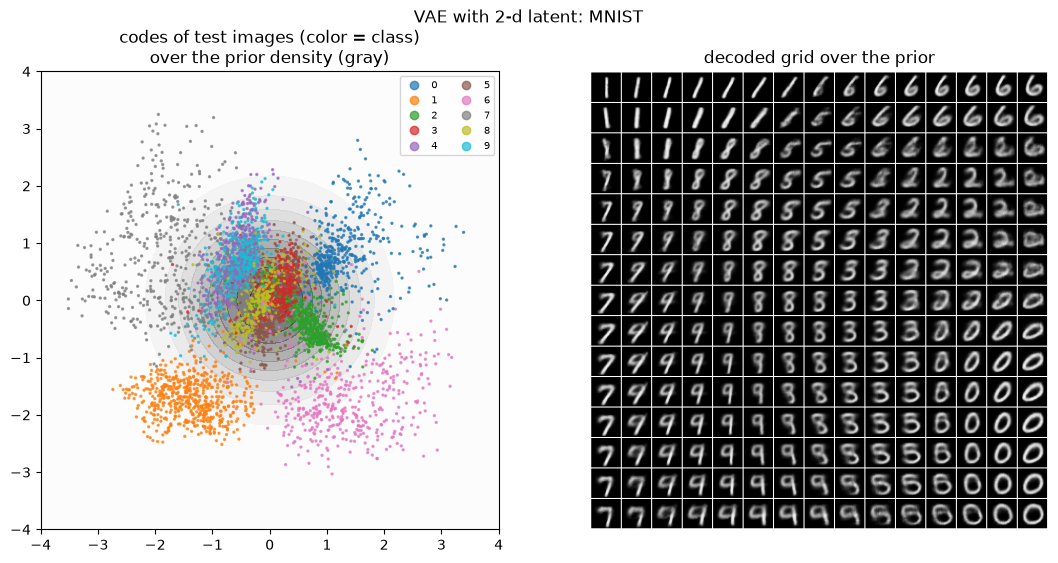

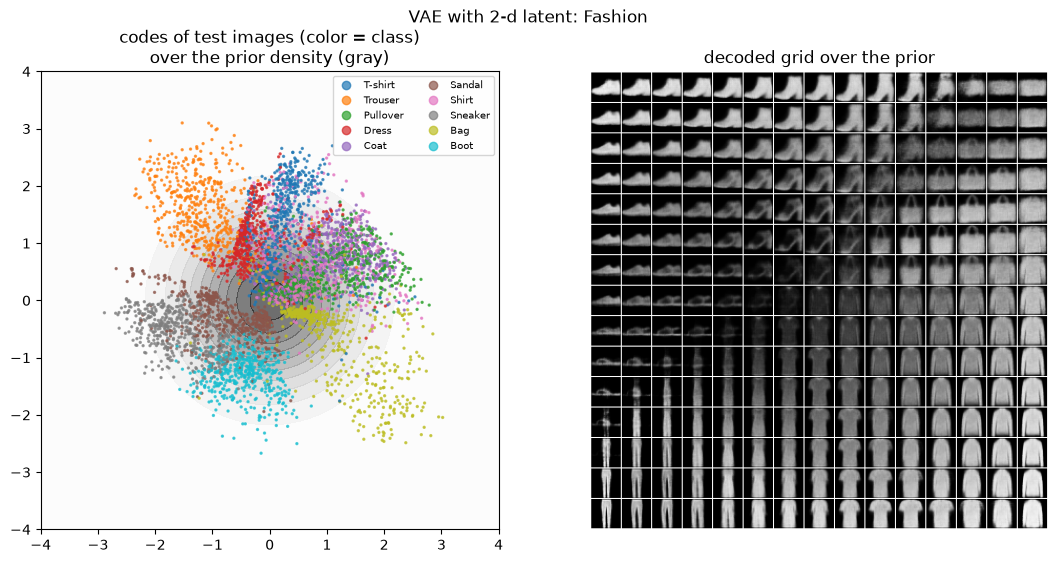

In [21]:
@torch.no_grad()
def plot_latent_space(model, data, title, class_names, save_as=None):
    model.eval()
    mu, _ = model.encode(data['test'][:5000].to(device))
    mu = mu.cpu().numpy()
    labels = data['test_labels'][:5000].numpy()

    grid_1d = torch.linspace(-4, 4, 200)
    gx, gy = torch.meshgrid(grid_1d, grid_1d, indexing='xy')
    grid = torch.stack([gx.flatten(), gy.flatten()], dim=1).to(device)
    prior_density = model.log_prior(grid).exp().reshape(200, 200).cpu().numpy()
    gx, gy = gx.numpy(), gy.numpy()

    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    axes[0].contourf(gx, gy, prior_density, levels=12, cmap='Greys', alpha=0.6)
    points = axes[0].scatter(mu[:, 0], mu[:, 1], c=labels, cmap='tab10', s=2, alpha=0.7)
    axes[0].legend(points.legend_elements()[0], class_names, fontsize=7, ncol=2, loc='upper right')
    axes[0].set_xlim(-4, 4); axes[0].set_ylim(-4, 4); axes[0].set_aspect('equal')
    axes[0].set_title('codes of test images (color = class)\nover the prior density (gray)')

    # a 15 x 15 grid of evenly spaced *probabilities* of the base N(0, I), mapped to z
    q = torch.distributions.Normal(0, 1).icdf(torch.linspace(0.04, 0.96, 15))
    qx, qy = torch.meshgrid(q, q, indexing='xy')
    u = torch.stack([qx.flatten(), qy.flatten()], dim=1).to(device)
    z = model.base_to_latent(u) if hasattr(model, 'base_to_latent') else u
    show_images(torch.sigmoid(model.decoder(z)), nrow=15, title='decoded grid over the prior', ax=axes[1])
    fig.suptitle(title)
    if save_as:
        plt.savefig(save_as, dpi=120, bbox_inches='tight')
    plt.show()


torch.manual_seed(0)
vae2_mnist = VAE(2)
hist_vae2_mnist = train_vae(vae2_mnist, mnist, epochs=20, warmup_epochs=5)
torch.manual_seed(0)
vae2_fashion = VAE(2)
hist_vae2_fashion = train_vae(vae2_fashion, fashion, epochs=20, warmup_epochs=5)

plot_latent_space(vae2_mnist, mnist, 'VAE with 2-d latent: MNIST', [str(i) for i in range(10)], 'figures/part2_latent2d_mnist.png')
plot_latent_space(vae2_fashion, fashion, 'VAE with 2-d latent: Fashion', FASHION_CLASSES, 'figures/part2_latent2d_fashion.png')

**What to notice:** some classes sit far from the center, where `N(0, I)` has little mass, and some regions of high prior density have few real codes. Samples from those regions decode into strange in-between images. These are the **"prior holes"**.

---
# Part 3: f-VAE (VAE with a RealNVP flow in the latent space)

**Problem from Part 2:** the prior N(0, I) is a simple round blob, but the real codes form an irregular shape. The KL term tries to squeeze them into the blob, but never fully succeeds → holes → bad samples, and some likelihood is wasted.

**Fix:** let the prior **learn** its shape. We take a RealNVP flow `f` (from the last homework) that maps a code `z` to a "simple" vector `u`:

$$\log p(z) = \log \mathcal{N}\big(f(z);\ 0, I\big) + \log\left|\det \frac{\partial f}{\partial z}\right|$$

- **Training:** the flow is trained together with the encoder and decoder. It learns to put probability where the real codes are.
- **Sampling:** `u ~ N(0, I)` → `z = f⁻¹(u)` → decoder → image.
- **The KL term** has no closed form any more, so we estimate it with the sampled `z`:
  $\text{KL} \approx \log q(z \mid x) - \log p_{\text{flow}}(z)$

Differences from the HW1 RealNVP: here the flow works on a **16-number vector**, not on an image, so simple fully-connected coupling layers are enough (no checkerboard / multi-scale needed).

### Coupling layer (same idea as HW1)
The mask splits `z` into two halves. The masked half **stays the same**; the other half is scaled by `exp(s)` and shifted by `t`, where `s` and `t` are computed from the masked half.
- Easy to invert: `z = (u − t) · exp(−s)`.
- Easy log-determinant: just `sum(s)`.

The last layer starts at **zero**, so at the start the flow is the identity (u = z), which makes training stable. `tanh` keeps the scales from exploding.

In [22]:
class CouplingLayer(nn.Module):
    def __init__(self, size, hidden, mask):
        super().__init__()
        self.register_buffer('mask', mask.float())
        self.net = nn.Sequential(
            nn.Linear(size, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 2 * size),
        )
        nn.init.zeros_(self.net[-1].weight)     # start as the identity map
        nn.init.zeros_(self.net[-1].bias)
        self.scale = nn.Parameter(torch.ones(size))

    def _s_t(self, z_masked):
        s, t = self.net(z_masked).chunk(2, dim=1)
        s = self.scale * torch.tanh(s)
        return s * (1 - self.mask), t * (1 - self.mask)   # only the NOT-masked half is changed

    def forward(self, z):          # z -> u
        s, t = self._s_t(z * self.mask)
        return z * torch.exp(s) + t, s.sum(dim=1)

    def inverse(self, u):          # u -> z
        s, t = self._s_t(u * self.mask)
        return (u - t) * torch.exp(-s)


class RealNVP(nn.Module):
    def __init__(self, size, n_layers=8, hidden=256):
        super().__init__()
        self.size = size
        index = torch.arange(size)
        even_odd = (index % 2 == 0)              # mask type 1: even / odd positions
        halves = (index < size // 2)             # mask type 2: first half / second half
        masks = []
        for k in range(n_layers):
            m = even_odd if (k // 2) % 2 == 0 else halves
            masks.append(m if k % 2 == 0 else ~m)    # flip every layer, so every number gets changed
        self.layers = nn.ModuleList([CouplingLayer(size, hidden, m) for m in masks])

    def forward(self, z):                      # z -> u, plus total log-determinant
        log_det = torch.zeros(len(z), device=z.device)
        for layer in self.layers:
            z, ld = layer(z)
            log_det = log_det + ld
        return z, log_det

    def inverse(self, u):                      # u -> z
        for layer in reversed(self.layers):
            u = layer.inverse(u)
        return u

    def log_prob(self, z):
        u, log_det = self.forward(z)
        return (-0.5 * u ** 2 - 0.5 * LOG_2PI).sum(dim=1) + log_det

### Check that the flow is correct
As in HW1: (1) going forward and back must give the same vector, (2) our cheap log-determinant must equal the real one, computed from the full Jacobian matrix.
We randomize the weights a bit first; otherwise the flow is the identity and the test would be too easy.

In [23]:
torch.manual_seed(0)
flow = RealNVP(16, n_layers=8, hidden=64)
with torch.no_grad():
    for p in flow.parameters():
        p += 0.1 * torch.randn_like(p)

z = torch.randn(4, 16)
u, log_det = flow(z)
print('invertible:', torch.allclose(flow.inverse(u), z, atol=1e-5))
J = torch.autograd.functional.jacobian(lambda v: flow(v.unsqueeze(0))[0][0], z[0])
print('log-det from the flow:', round(log_det[0].item(), 5), '  real:', round(torch.slogdet(J)[1].item(), 5))

invertible: True
log-det from the flow: -0.18158   real: -0.18158


### The f-VAE
It **inherits everything** from the VAE (same encoder, decoder, training loop, metrics). We only replace the parts that involve the prior:
- `kl`: the Monte-Carlo estimate `log q(z|x) − log p_flow(z)`
- `log_prior`: the flow's density
- `sample_z`: `u ~ N(0, I)`, then invert the flow

In [24]:
class FlowVAE(VAE):
    def __init__(self, latent_size):
        super().__init__(latent_size)
        self.prior = RealNVP(latent_size, n_layers=8, hidden=256)

    def kl(self, z, mu, logvar):
        return log_normal(z, mu, logvar) - self.prior.log_prob(z)

    def log_prior(self, z):
        return self.prior.log_prob(z)

    def base_to_latent(self, u):
        return self.prior.inverse(u)

    @torch.no_grad()
    def sample_z(self, n, temperature=1.0):
        u = torch.randn(n, self.latent_size, device=device) * temperature
        return self.prior.inverse(u)


print('VAE parameters:  ', sum(p.numel() for p in VAE(16).parameters()))
print('f-VAE parameters:', sum(p.numel() for p in FlowVAE(16).parameters()))

VAE parameters:   3306721
f-VAE parameters: 3933793


### Train the f-VAE (latent 16) on both datasets
Exactly the same settings as the VAE (40 epochs, KL warm-up), so the comparison is fair. A bit slower because of the flow.

In [25]:
torch.manual_seed(0)
fvae_mnist = FlowVAE(16)
hist_fvae_mnist = train_vae(fvae_mnist, mnist, epochs=40)

epoch  1/40  beta 0.10  train -ELBO  142.17  val -ELBO  111.76  (recon  71.29, KL 40.48)


epoch  5/40  beta 0.50  train -ELBO   94.44  val -ELBO   94.40  (recon  66.87, KL 27.53)


epoch 10/40  beta 1.00  train -ELBO   90.36  val -ELBO   90.73  (recon  68.12, KL 22.61)


epoch 15/40  beta 1.00  train -ELBO   89.05  val -ELBO   89.88  (recon  67.68, KL 22.19)


epoch 20/40  beta 1.00  train -ELBO   88.30  val -ELBO   89.33  (recon  67.83, KL 21.50)


epoch 25/40  beta 1.00  train -ELBO   87.65  val -ELBO   89.01  (recon  67.53, KL 21.48)


epoch 30/40  beta 1.00  train -ELBO   87.19  val -ELBO   88.73  (recon  66.57, KL 22.16)


epoch 35/40  beta 1.00  train -ELBO   86.88  val -ELBO   88.16  (recon  65.77, KL 22.39)


epoch 40/40  beta 1.00  train -ELBO   86.64  val -ELBO   88.32  (recon  65.96, KL 22.35)


In [26]:
torch.manual_seed(0)
fvae_fashion = FlowVAE(16)
hist_fvae_fashion = train_vae(fvae_fashion, fashion, epochs=40)

epoch  1/40  beta 0.10  train -ELBO  272.99  val -ELBO  252.75  (recon 218.60, KL 34.16)


epoch  5/40  beta 0.50  train -ELBO  235.43  val -ELBO  236.01  (recon 213.34, KL 22.67)


epoch 10/40  beta 1.00  train -ELBO  231.83  val -ELBO  232.90  (recon 216.28, KL 16.63)


epoch 15/40  beta 1.00  train -ELBO  230.75  val -ELBO  231.93  (recon 215.37, KL 16.56)


epoch 20/40  beta 1.00  train -ELBO  230.21  val -ELBO  231.78  (recon 215.26, KL 16.51)


epoch 25/40  beta 1.00  train -ELBO  229.71  val -ELBO  231.56  (recon 215.27, KL 16.30)


epoch 30/40  beta 1.00  train -ELBO  229.42  val -ELBO  231.09  (recon 214.11, KL 16.98)


epoch 35/40  beta 1.00  train -ELBO  229.16  val -ELBO  230.90  (recon 214.04, KL 16.86)


epoch 40/40  beta 1.00  train -ELBO  228.86  val -ELBO  230.55  (recon 213.37, KL 17.18)


### VAE vs f-VAE: learning curves and test numbers

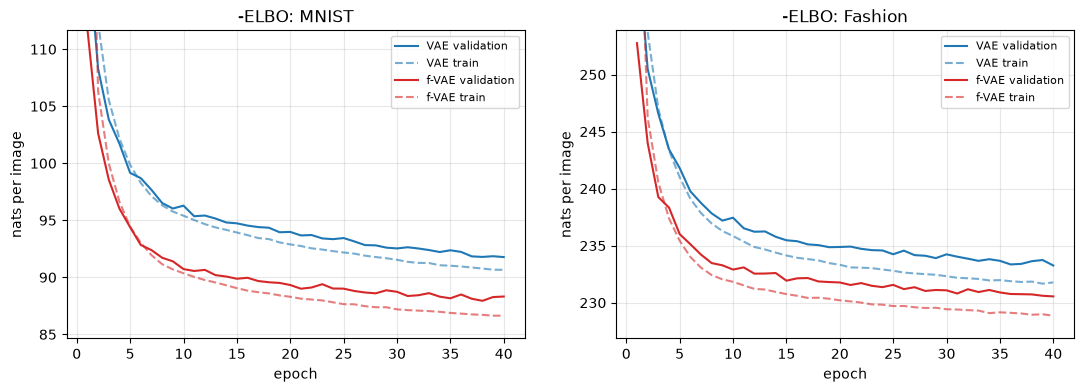

,recon,kl,nelbo,iwae_nll
"VAE (d=16), MNIST",65.81,25.44,91.25,87.18
"VAE (d=16), Fashion",215.47,18.47,233.94,230.90
"f-VAE (d=16), MNIST",65.32,22.31,87.62,84.35
"f-VAE (d=16), Fashion",214.08,17.01,231.09,228.74


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name, h_vae, h_fvae in [(axes[0], 'MNIST', hist_vae_mnist, hist_fvae_mnist),
                                (axes[1], 'Fashion', hist_vae_fashion, hist_fvae_fashion)]:
    epochs = range(1, len(h_vae['val']) + 1)
    ax.plot(epochs, h_vae['val'], color='C0', label='VAE validation')
    ax.plot(epochs, h_vae['train'], color='C0', ls='--', alpha=0.6, label='VAE train')
    ax.plot(epochs, h_fvae['val'], color='C3', label='f-VAE validation')
    ax.plot(epochs, h_fvae['train'], color='C3', ls='--', alpha=0.6, label='f-VAE train')
    low = min(h_fvae['train'])
    ax.set_ylim(low - 2, low + 25)
    ax.set_title(f'-ELBO: {name}'); ax.set_xlabel('epoch'); ax.set_ylabel('nats per image')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.savefig('figures/part3_curves_vae_vs_fvae.png', dpi=120, bbox_inches='tight')
plt.show()

results['f-VAE (d=16), MNIST'] = test_metrics(fvae_mnist, mnist)
results['f-VAE (d=16), Fashion'] = test_metrics(fvae_fashion, fashion)
pd.DataFrame(results).T.round(2)

### VAE vs f-VAE: samples
Same random seed on both sides.

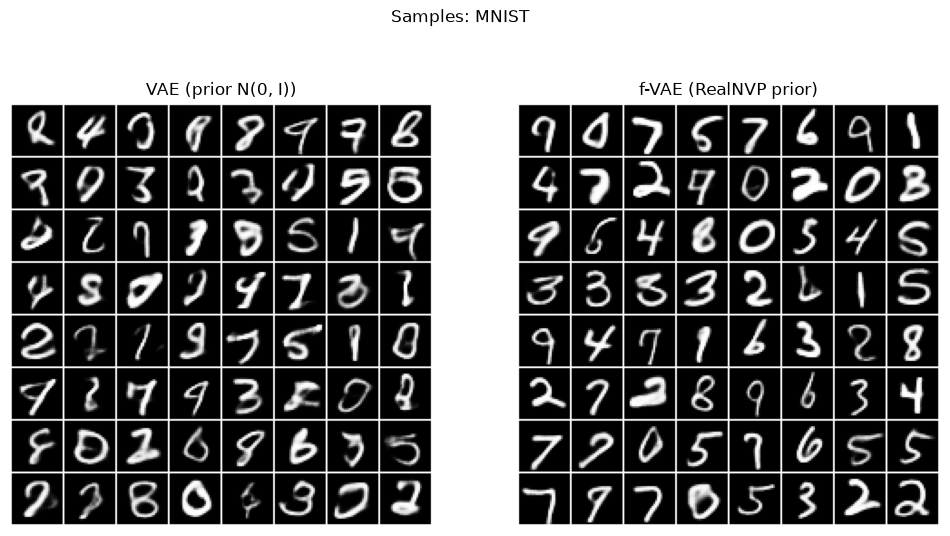

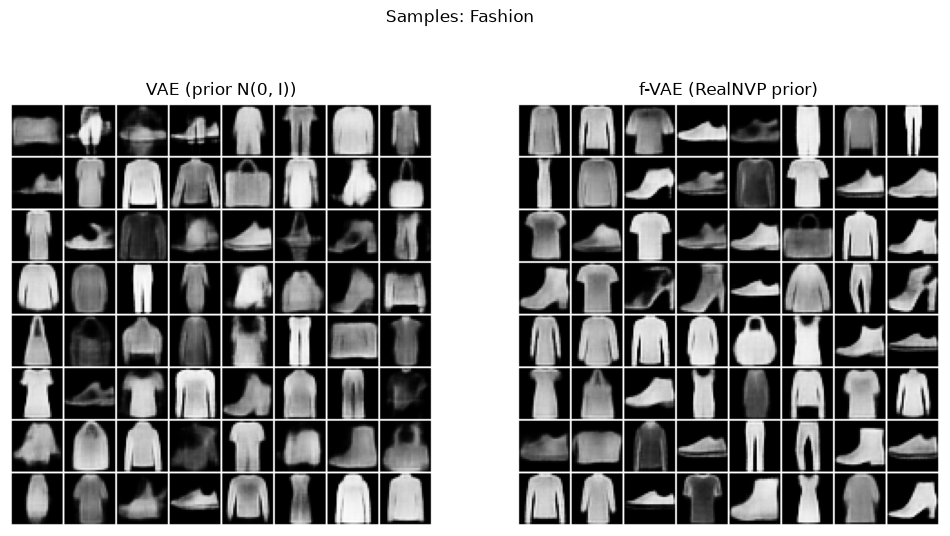

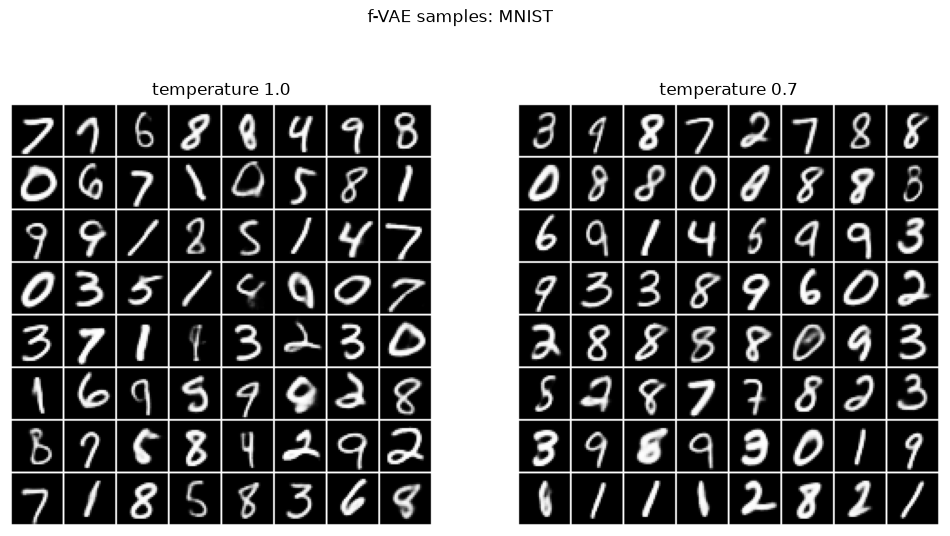

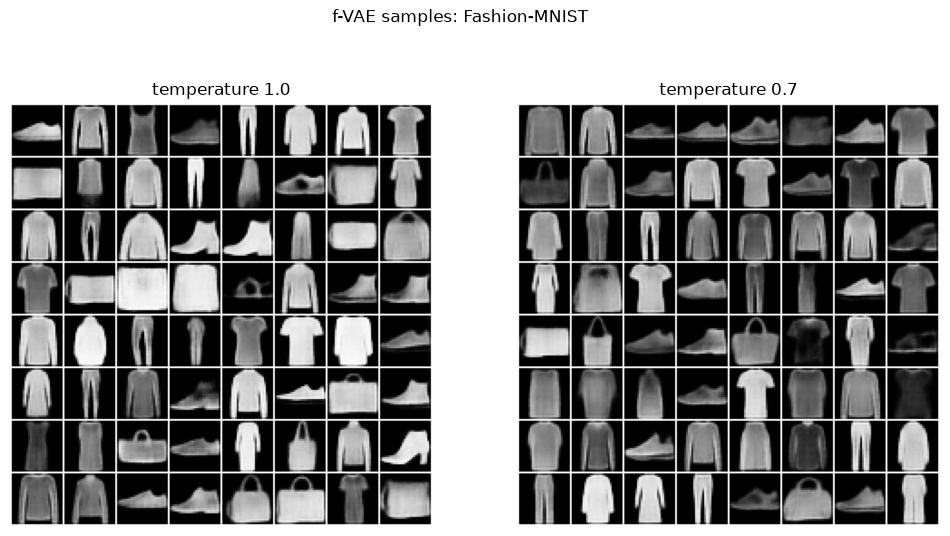

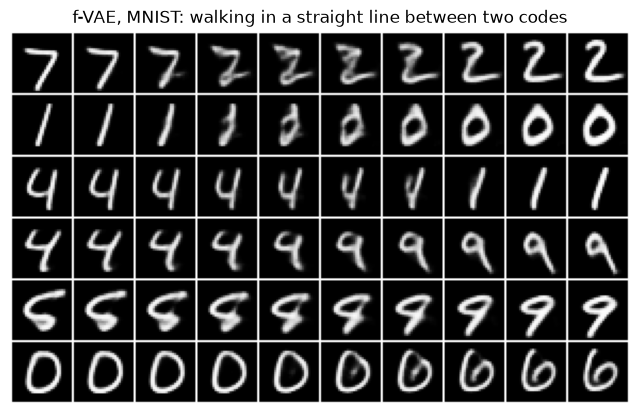

In [28]:
for name, vae_model, fvae_model in [('MNIST', vae_mnist, fvae_mnist), ('Fashion', vae_fashion, fvae_fashion)]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.3))
    torch.manual_seed(123)
    show_images(vae_model.sample(64), nrow=8, title='VAE (prior N(0, I))', ax=axes[0])
    torch.manual_seed(123)
    show_images(fvae_model.sample(64), nrow=8, title='f-VAE (RealNVP prior)', ax=axes[1])
    fig.suptitle(f'Samples: {name}')
    plt.savefig(f'figures/part3_samples_vae_vs_fvae_{name.lower()}.png', dpi=120, bbox_inches='tight')
    plt.show()

show_samples(fvae_mnist, 'f-VAE samples: MNIST', 'figures/part3_fvae_samples_mnist.png')
show_samples(fvae_fashion, 'f-VAE samples: Fashion-MNIST', 'figures/part3_fvae_samples_fashion.png')
show_interpolations(fvae_mnist, mnist, 'f-VAE, MNIST')

### Per-class comparison
Does the flow prior help on all classes, or only on some?

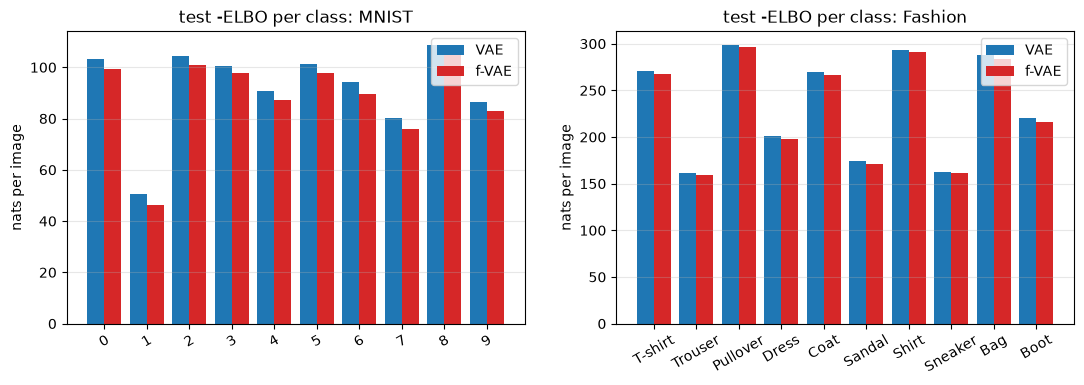

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, vae_model, fvae_model, data, labels) in zip(axes, [
        ('MNIST', vae_mnist, fvae_mnist, mnist, [str(i) for i in range(10)]),
        ('Fashion', vae_fashion, fvae_fashion, fashion, FASHION_CLASSES)]):
    positions = np.arange(10)
    ax.bar(positions - 0.2, nelbo_per_class(vae_model, data), 0.4, color='C0', label='VAE')
    ax.bar(positions + 0.2, nelbo_per_class(fvae_model, data), 0.4, color='C3', label='f-VAE')
    ax.set_xticks(positions, labels, rotation=30)
    ax.set_title(f'test -ELBO per class: {name}'); ax.set_ylabel('nats per image')
    ax.grid(alpha=0.3, axis='y'); ax.legend()
plt.savefig('figures/part3_per_class.png', dpi=120, bbox_inches='tight')
plt.show()

### What did the flow prior learn? (2-d latent)
Same 2-d experiment as in Part 2, now with a flow prior. Compare the gray prior density with Part 2's round blob: the flow prior should **follow the shape of the real codes**.
The right grid decodes evenly spaced points of `u ~ N(0, I)` pushed through the flow, i.e. what the f-VAE actually samples.

epoch  1/20  beta 0.20  train -ELBO  177.12  val -ELBO  162.08  (recon 155.39, KL  6.69)


epoch  5/20  beta 1.00  train -ELBO  152.77  val -ELBO  151.85  (recon 146.25, KL  5.60)


epoch 10/20  beta 1.00  train -ELBO  149.41  val -ELBO  148.92  (recon 142.93, KL  5.98)


epoch 15/20  beta 1.00  train -ELBO  147.54  val -ELBO  146.64  (recon 140.71, KL  5.93)


epoch 20/20  beta 1.00  train -ELBO  146.40  val -ELBO  145.26  (recon 139.11, KL  6.15)


epoch  1/20  beta 0.20  train -ELBO  284.69  val -ELBO  271.30  (recon 263.79, KL  7.51)


epoch  5/20  beta 1.00  train -ELBO  261.78  val -ELBO  263.86  (recon 257.96, KL  5.90)


epoch 10/20  beta 1.00  train -ELBO  259.51  val -ELBO  261.33  (recon 255.59, KL  5.74)


epoch 15/20  beta 1.00  train -ELBO  258.34  val -ELBO  260.58  (recon 254.44, KL  6.14)


epoch 20/20  beta 1.00  train -ELBO  257.53  val -ELBO  259.04  (recon 252.97, KL  6.07)


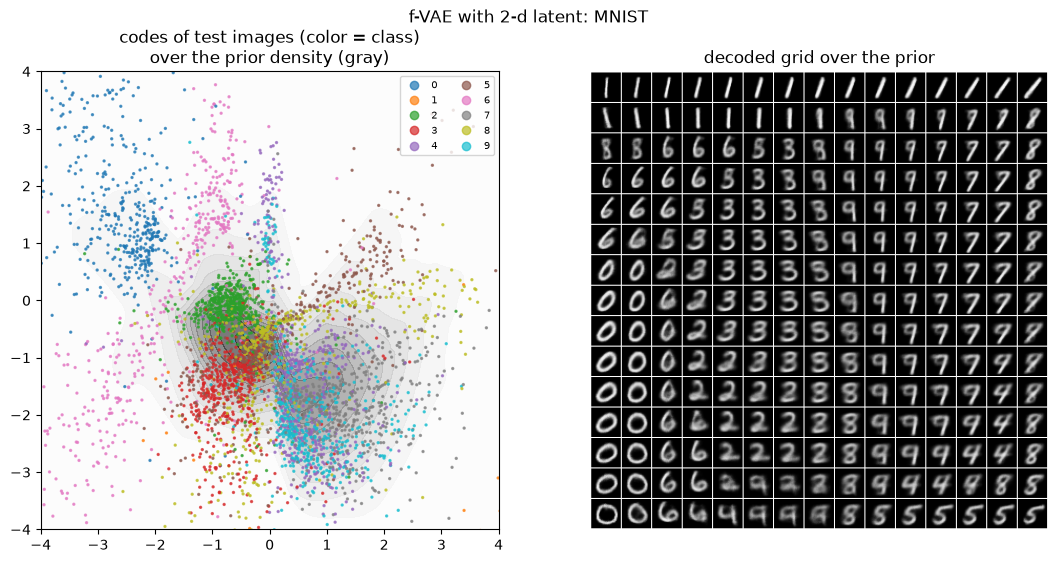

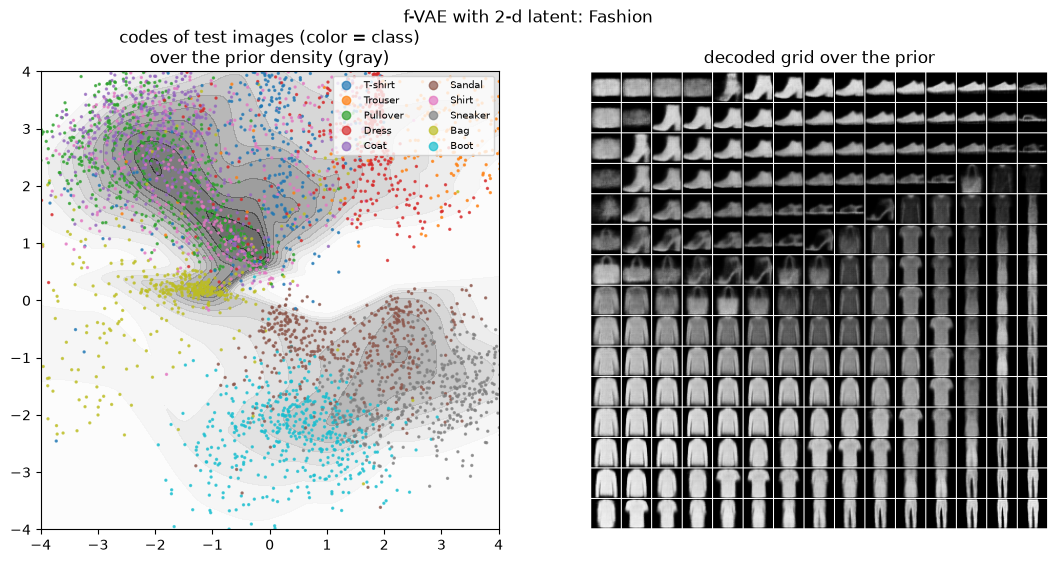

In [30]:
torch.manual_seed(0)
fvae2_mnist = FlowVAE(2)
hist_fvae2_mnist = train_vae(fvae2_mnist, mnist, epochs=20, warmup_epochs=5)
torch.manual_seed(0)
fvae2_fashion = FlowVAE(2)
hist_fvae2_fashion = train_vae(fvae2_fashion, fashion, epochs=20, warmup_epochs=5)

plot_latent_space(fvae2_mnist, mnist, 'f-VAE with 2-d latent: MNIST', [str(i) for i in range(10)], 'figures/part3_latent2d_mnist.png')
plot_latent_space(fvae2_fashion, fashion, 'f-VAE with 2-d latent: Fashion', FASHION_CLASSES, 'figures/part3_latent2d_fashion.png')

---
## Final results table
All numbers are on the **test set**, in **nats per image** (lower = better).
- `recon` + `kl` = `nelbo` (the −ELBO, an upper bound on −log p(x))
- `iwae_nll` = the tighter likelihood estimate (K = 100)

In [31]:
results['VAE (d=2), MNIST'] = test_metrics(vae2_mnist, mnist)
results['f-VAE (d=2), MNIST'] = test_metrics(fvae2_mnist, mnist)
results['VAE (d=2), Fashion'] = test_metrics(vae2_fashion, fashion)
results['f-VAE (d=2), Fashion'] = test_metrics(fvae2_fashion, fashion)

final = pd.DataFrame(results).T.round(2)
final.to_csv('figures/results_table.csv')
final

,recon,kl,nelbo,iwae_nll
"VAE (d=16), MNIST",65.81,25.44,91.25,87.18
"VAE (d=16), Fashion",215.47,18.47,233.94,230.90
"f-VAE (d=16), MNIST",65.32,22.31,87.62,84.35
"f-VAE (d=16), Fashion",214.08,17.01,231.09,228.74
"VAE (d=2), MNIST",138.61,6.48,145.09,141.54
"f-VAE (d=2), MNIST",140.26,6.11,146.37,142.80
"VAE (d=2), Fashion",253.45,6.15,259.60,257.54
"f-VAE (d=2), Fashion",253.03,6.05,259.08,257.05


### Save the trained models
So you can load them later without retraining: `model = FlowVAE(16); model.load_state_dict(torch.load('checkpoints/fvae_mnist.pt'))`.

In [32]:
for name, model in [('vae_mnist', vae_mnist), ('vae_fashion', vae_fashion), ('fvae_mnist', fvae_mnist),
                    ('fvae_fashion', fvae_fashion), ('vae2_mnist', vae2_mnist), ('vae2_fashion', vae2_fashion),
                    ('fvae2_mnist', fvae2_mnist), ('fvae2_fashion', fvae2_fashion)]:
    torch.save(model.state_dict(), f'checkpoints/{name}.pt')
print('saved')

saved


---
## Questions to think about for the report
- **Part 1:** Where is the "elbow" of the error curve, and why does it exist? Why does the autoencoder beat PCA, and why does PCA catch up at large sizes? Why is Fashion *easier* at tiny codes but *harder* at large ones?
- **Part 2:** Why does the reconstruction loss go *up* during the KL warm-up? Why are VAE samples blurrier than AE reconstructions? Which classes are hardest, and why? What do the "prior holes" look like in the 2-d plot?
- **Part 3:** How many nats does the flow prior gain, and does it help every class? Why does it help at 16 dimensions but hardly at 2? Why are Fashion samples still blurry even with the better prior?
- **Improvements:** longer training, bigger networks, a more powerful decoder (e.g. PixelCNN), a flow in the *encoder* too, a hierarchical VAE.